In [109]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import linalg, stats
from sklearn.datasets import load_iris, load_breast_cancer, make_moons

seed = 42

### Problem 1. Inverse-Transform Sampling: Uniform to Exponential

**(b) Y samples based on X** \
$\lambda$ = 2, seed = 42, N = 100,000

In [10]:
rng = np.random.default_rng(seed)

lam = 2
N = 100000

X = rng.uniform(0, 1, N)
Y = -np.log(X) / lam

print(f"{"Sample mean:": <18} {Y.mean(): .8f};  {"Sample var:": <16} {Y.var(): .8f}")

R_mean  = 1 / lam
R_var   = 1 / lam ** 2

print(f"{"Theoretical mean:": <18} {R_mean: .8f};  {"Theoretical var:": <16} {R_var: .8f}")

Sample mean:        0.49964471;  Sample var:       0.25198023
Theoretical mean:   0.50000000;  Theoretical var:  0.25000000


**(c) Histogram of simulated Y samples**

/tmp/ipykernel_1129/3987762180.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


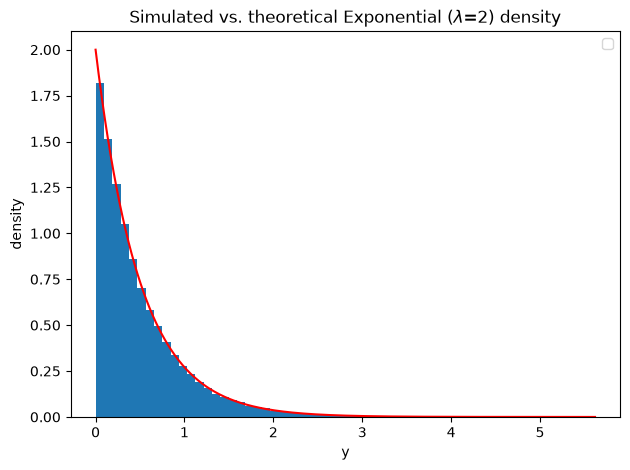

In [12]:
plt.hist(Y, bins=60, density=True)
y_dist = np.linspace(0, Y.max(), 500)
plt.plot(y_dist, lam*np.exp(-lam*y_dist), color="red")

plt.xlabel("y")
plt.ylabel("density")
plt.title(f"Simulated vs. theoretical Exponential ($\\lambda$={lam}) density")
plt.legend()
plt.tight_layout()
plt.show()

### Problem 2. Joint, Marginal, and Conditional Distributions of Two Discrete Random Variables

|        | Y = 0  | Y = 1  |
|--------|--------|--------|
| X = 0  | 0.25   | 0.05   |
| X = 1  | 0.10   | 0.20   |
| X = 2  | 0.15   | 0.25   |

In [15]:
P = np.array([[0.25, 0.05],
              [0.10, 0.20],
              [0.15, 0.25]])
x_vals, y_vals = np.array([0,1,2]), np.array([0,1])

pX, pY = P.sum(axis=1), P.sum(axis=0)
pY_given_X1 = P[1,:] / pX[1]    # Test X = 1
independent = np.allclose(np.outer(pX, pY), P)

EX  = (x_vals*pX).sum()
VX  = (x_vals**2*pX).sum() - EX**2
EY  = (y_vals*pY).sum()
VY  = (y_vals**2*pY).sum() - EY**2
EXY = sum(x_vals[i]*y_vals[j]*P[i,j] for i in range(3) for j in range(2))
VXY = EXY - EX*EY
rho = VXY / np.sqrt(VX*VY)

print("a) pX:", pX, " pY:", pY)
print("b) pY|X=1:", pY_given_X1, " Independence: ", independent)
print(f"c) E[X]={EX}, V(X)={VX}")
print(f"   E[Y]={EY}, V(Y)={VY}")
print(f"   E[XY]={EXY}, Cov(X,Y)={VXY}, rho={rho}")

a) pX: [0.3 0.3 0.4]  pY: [0.5 0.5]
b) pY|X=1: [0.33333333 0.66666667]  Independence:  False
c) E[X]=1.1, V(X)=0.69
   E[Y]=0.5, V(Y)=0.25
   E[XY]=0.7, Cov(X,Y)=0.1499999999999999, rho=0.3611575592573074


### Problem 3. Covariance and Correlation from Real Data

**(b) Iris Dataset**

In [16]:
data = load_iris()
X = data.data[:, 0]   # sepal length (cm)
Y = data.data[:, 2]   # petal length (cm)

mean_vec = np.array([X.mean(), Y.mean()])
cov = np.cov(X, Y, ddof=1)          # 2x2 sample covariance matrix
rho = cov[0,1] / np.sqrt(cov[0,0]*cov[1,1])

print("mean vector:", mean_vec)
print("covariance matrix:\n", cov)
print("correlation rho:", rho)

mean vector: [5.84333333 3.758     ]
covariance matrix:
 [[0.68569351 1.27431544]
 [1.27431544 3.11627785]]
correlation rho: 0.8717537758865832


**(c) Applying formulas**

In [17]:
a, b, c, d = 2, -1, 1, 3
VX, VY, CXY = cov[0,0], cov[1,1], cov[0,1]
V_formula = a*c*VX + b*d*VY + (a*d + b*c)*CXY

U = a*X + b*Y          # 2X - Y
W = c*X + d*Y          # X + 3Y
V_direct = np.cov(U, W, ddof=1)[0,1]

print("V(2X-Y, X+3Y) calculated :", V_formula)
print("V(2X-Y, X+3Y) direct     :", V_direct)

V(2X-Y, X+3Y) calculated : -1.6058693512304325
V(2X-Y, X+3Y) direct     : -1.605869351230424


### Problem 4. Random Vectors and Linear Transformations

$$ \mu_X =
\begin{bmatrix}
1 \\ 2 \\ 3
\end{bmatrix}, 

\sigma_X =
\begin{bmatrix}
1 & 1.8 & 2.43 \\ 1.8 & 4 & 5.4 \\ 2.43 & 5.4 & 9
\end{bmatrix}$$

<center>

Using $Y = AX + b$

</center>

$$ \mu_Y =
\begin{bmatrix}
3 \\ 2 \\ 1
\end{bmatrix}, 

\Sigma_Y =
\begin{bmatrix}
9 & -5.4 & -2.43 \\ -5.4 & 4 & 1.8 \\ -2.43 & 1.8 & 1
\end{bmatrix}$$

**(a) Transformation 1: Z Matrix**

Using $Z = A_1X + b_1$

In [18]:
muX = np.array([1., 2., 3.])
SigX = np.array([[1, 1.8, 2.43],
                  [1.8, 4, 5.4],
                  [2.43, 5.4, 9.]])

SigX_sqrt = linalg.sqrtm(SigX).real
A1 = np.linalg.inv(SigX_sqrt)
b1 = -A1 @ muX
print("A1:\n", A1)
print("b1: ", b1, "\n")

muZ = A1 @ muX + b1
SigZ = A1 @ SigX @ A1.T
print("muZ:", muZ)
print("SigZ:\n", SigZ)

A1:
 [[ 2.18346522 -0.69475997 -0.11378095]
 [-0.69475997  1.30024694 -0.45633916]
 [-0.11378095 -0.45633916  0.60299568]]
b1:  [-0.45260242 -0.53671643 -0.78252776] 

muZ: [0. 0. 0.]
SigZ:
 [[ 1.00000000e+00  2.91691098e-15  9.82787632e-16]
 [ 3.38856326e-15  1.00000000e+00 -1.49035388e-15]
 [ 9.77815218e-16 -2.08814071e-15  1.00000000e+00]]


**(b) Transformation 2: Y Matrix**

Using $Y = A_2Z + b_2$

In [19]:
muY = np.array([3., 2., 1.])
SigY = np.array([[9, -5.4, -2.43],
                   [-5.4, 4, 1.8],
                   [-2.43, 1.8, 1.]])

A2 = linalg.sqrtm(SigY).real
b2 = muY.copy() 
print("A2:\n", A2)
print("b2: ", b2, "\n")

muY_check = A2 @ muZ + b2
SigY_check = A2 @ SigZ @ A2.T
print("muY check:", muY_check)
print("SigY check:\n", SigY_check)

A2:
 [[ 2.68624191 -1.2260143  -0.53008805]
 [-1.2260143   1.48618834  0.53678036]
 [-0.53008805  0.53678036  0.65640955]]
b2:  [3. 2. 1.] 

muY check: [3. 2. 1.]
SigY check:
 [[ 9.   -5.4  -2.43]
 [-5.4   4.    1.8 ]
 [-2.43  1.8   1.  ]]


**(c) Overall transformation matrix**

$Z = A_1X + b_1, Y = A_2Z + b_2$

Substituting: $Y = A_2(A_1X + b_1) + b_2 = A_2A_1X + (A_2b_1 + b_2)$ \
$A = A_2A_1, b = A_2b_1 + b_2$

In [20]:
A = A2 @ A1
b = A2 @ b1 + b2
print("A =\n", A)
print("b =", b, "\n")

muY_final = A @ muX + b
SigY_final = A @ SigX @ A.T
print("Final muY:", muY_final)
print("Final SigY:\n", SigY_final)

A =
 [[ 6.77741537 -3.21851475 -0.06580564]
 [-3.77057913  2.5392436  -0.21503263]
 [-1.60504924  0.76668559  0.21117215]]
b = [2.85703105 1.33718981 0.4381616 ] 

Final muY: [3. 2. 1.]
Final SigY:
 [[ 9.   -5.4  -2.43]
 [-5.4   4.    1.8 ]
 [-2.43  1.8   1.  ]]


### Problem 5. Conditional Distributions of a Multivariate Gaussian

$$V = (X_1,X_2,X_3)^T \sim N(\mu,\Sigma), \mu = 0, \Sigma = \begin{bmatrix} 4 & 2 & 1 \\ 2 & 3 & 0.5 \\ 1 & 0.5 & 2 \end{bmatrix}$$

**(c) Empirical comparison**

In [ ]:
mu = np.zeros(3)
Sigma = np.array([[4, 2, 1],
                   [2, 3, 0.5],
                   [1, 0.5, 2]])

N = int(2e6)
V = rng.multivariate_normal(mu, Sigma, size=N)

tolerance = 0.03
mask = np.abs(V[:, 2] - 1.5) < tolerance
print("samples retained:", mask.sum(), "\n")

emp_mean = V[mask, :2].mean(axis=0)
emp_cov = np.cov(V[mask, 0], V[mask, 1], ddof=1)
cf_mean = np.array([0.75, 0.375])
cf_cov = np.array([[3.5, 1.75],
                   [1.75, 2.875]])

print("Empirical mean:  ", emp_mean)
print("Closed-form mean:", cf_mean,"\n")

print("Empirical cov:\n", emp_cov)
print("Closed-form cov:\n", cf_cov)


samples retained: 19428 

Empirical mean:   [0.77212229 0.39436917]
Closed-form mean: [0.75  0.375] 

Empirical cov:
 [[3.53784785 1.75840931]
 [1.75840931 2.87513737]]
Closed-form cov:
 [[3.5   1.75 ]
 [1.75  2.875]]


### Problem 6. Sums and Products of Independent Gaussian Random Variables

$$X \sim N(\mu_1,\sigma^2_1), Y \sim N(\mu_2,\sigma^2_2)$$

**(c) Empirical comparison**\
$\mu_1 = 2, \sigma_1 = 1, \mu_2 = -1, \sigma_2 = 2, N = 200,000$

In [22]:
mu1, s1 = 2, 1
mu2, s2 = -1, 2
var1, var2 = s1**2, s2**2
N = 200_000

X = rng.normal(mu1, s1, N)
Y = rng.normal(mu2, s2, N)
Z = X + Y

print("empirical mean Z:", Z.mean(), " theory:", mu1+mu2)
print("empirical var  Z:", Z.var(),  " theory:", var1+var2)

mu_star  = (mu1*var2 + mu2*var1) / (var1+var2)
var_star = (var1*var2) / (var1+var2)
print("mu_star:", mu_star, " var_star:", var_star)

empirical mean Z: 0.9980188048909078  theory: 1
empirical var  Z: 4.985278856543919  theory: 5
mu_star: 1.4  var_star: 0.8


### Problem 7. Bernoulli / Binomial Estimation on Real Data

i.i.d. $X_1,...,X_n \sim Bernoulli(q)$

**(b) WDBC Dataset**\
$X_i = 1$ if sample $i$ is malignant, and $X_i = 0$ otherwise.

In [23]:
data = load_breast_cancer()
print("target_names:", data.target_names)

malignant = (data.target == 0).astype(int)
n = len(malignant)
qhat = malignant.mean()
print("n =", n, " qhat (malignancy rate) =", qhat)

target_names: ['malignant' 'benign']
n = 569  qhat (malignancy rate) = 0.37258347978910367


**(c) Wald confidence interval and Wilson score interval**

In [24]:
z = stats.norm.ppf(0.975)
print("z: ", z)

# Wald
wald_hw = z * np.sqrt(qhat*(1-qhat)/n)
wald_ci = (qhat - wald_hw, qhat + wald_hw)

# Wilson score
denom = 1 + z**2/n
center = (qhat + z**2/(2*n)) / denom
wilson_hw = (z/denom) * np.sqrt(qhat*(1-qhat)/n + z**2/(4*n**2))
wilson_ci = (center - wilson_hw, center + wilson_hw)

print("Wald 95% CI:  ", wald_ci)
print("Wilson 95% CI:", wilson_ci)

z:  1.959963984540054
Wald 95% CI:   (np.float64(0.33285684938465654), np.float64(0.4123101101935508))
Wilson 95% CI: (np.float64(0.333835509125589), np.float64(0.41304035370300096))


**(d) Simulated check**

$N = 100,000$

In [99]:
N = 100000

sims = rng.binomial(n, qhat, N)
print(f"simulated mean: {sims.mean():.8f}; Theory n*qhat: {n*qhat:.8f}")
print(f"simulated var : {sims.var():.8f}; theory n*qhat*(1-qhat):{n*qhat*(1-qhat):.8f}")

simulated mean: 33.55643000; Theory n*qhat: 33.53251318
simulated var : 20.98677566; theory n*qhat*(1-qhat):21.03885273


### Problem 8. Categorical / Multinomial Estimation and Dirichlet Conjugacy

$\pi = (\pi_1,...,\pi_k)$

**(c) - (d) Subsample and MLE**

In [100]:
data = load_iris()
y = data.target

idx = rng.choice(len(y), size=90, replace=False)
sub_y = y[idx]
counts = np.array([np.sum(sub_y == k) for k in range(3)])
print("subsample class counts:", counts, "\n")

n = counts.sum()
mle = counts / n
print("MLE pihat:", mle)

alpha_prior = np.array([1, 1, 1])
post_alpha = alpha_prior + counts
print("posterior Dirichlet params:", post_alpha)

post_mean = post_alpha / post_alpha.sum()
print("posterior mean:", post_mean)

subsample class counts: [30 31 29] 

MLE pihat: [0.33333333 0.34444444 0.32222222]
posterior Dirichlet params: [31 32 30]
posterior mean: [0.33333333 0.34408602 0.32258065]


### Problem 9. Beta-Bernoulli Sequential Bayesian Updating

**(b) Simulating coin flips**

In [92]:
N = 50
q_true = 0.7
flips = (rng.uniform(0, 1, N) < q_true).astype(int)

alpha0, beta0 = 1, 1
a, b = alpha0, beta0
means, ci_lo, ci_hi = [], [], []

for x in flips:
    if x == 1:
        a += 1
    else:
        b += 1
    means.append(a / (a+b))
    lo, hi = stats.beta.ppf([0.05, 0.95], a, b)
    ci_lo.append(lo)
    ci_hi.append(hi)

print("successes:", flips.sum(), " failures:", N - flips.sum())
print("final (alpha, beta):", (a, b))

successes: 30  failures: 20
final (alpha, beta): (31, 21)


**(c) Posterior mean plot**

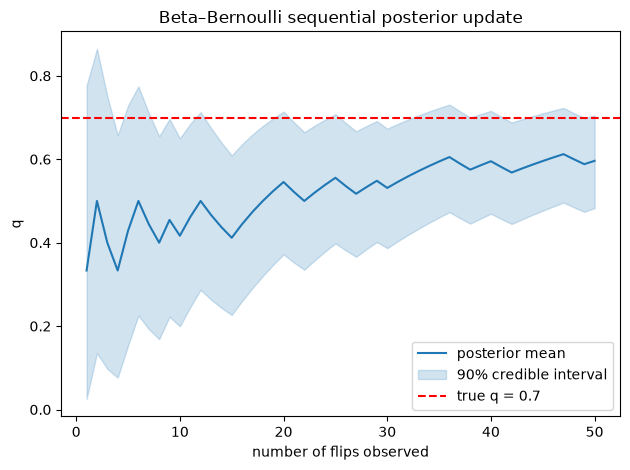

In [95]:
n_flips = np.arange(1, N+1)

plt.plot(n_flips, means, color='C0', label="posterior mean")
plt.fill_between(n_flips, ci_lo, ci_hi, color='C0', alpha=0.2, label="90% credible interval")
plt.axhline(q_true, color='r', linestyle='--', label=f"true q = {q_true}")
plt.xlabel("number of flips observed")
plt.ylabel("q")
plt.title("Beta–Bernoulli sequential posterior update")
plt.legend()
plt.tight_layout()
plt.savefig("p9_sequential_update.png", dpi=150)
plt.show()

**(d) Final posterior parameters**

In [96]:
final_mean = a / (a+b)
final_lo, final_hi = stats.beta.ppf([0.05, 0.95], a, b)
print("final posterior mean:", final_mean)
print("final 90% credible interval:", (final_lo, final_hi))
print("contains true q?", final_lo <= q_true <= final_hi)

final posterior mean: 0.5961538461538461
final 90% credible interval: (np.float64(0.4830716512438429), np.float64(0.7049888508764157))
contains true q? True


### Problem 10. Monte Carlo Simulation of a Gaussian Mixture Model

**(b) Numerical evaluation**

In [104]:
w = np.array([0.4, 0.6])
mus  = [np.array([0., 0.]), np.array([4., 3.])]
Sigs = [np.eye(2), np.array([[2, 0.5], [0.5, 1.]])]

mu = sum(w[k]*mus[k] for k in range(2))
within  = sum(w[k]*Sigs[k] for k in range(2))
between = sum(w[k]*np.outer(mus[k]-mu, mus[k]-mu) for k in range(2))
cov_overall = within + between

print("overall mean (mu):", mu)
print("within-component term:\n", within)
print("between-component term:\n", between, "\n")
print("total covariance:\n", cov_overall)

overall mean (mu): [2.4 1.8]
within-component term:
 [[1.6 0.3]
 [0.3 1. ]]
between-component term:
 [[3.84 2.88]
 [2.88 2.16]] 

total covariance:
 [[5.44 3.18]
 [3.18 3.16]]


**(c) Simulated verification**

In [108]:
N = 5000
Z = rng.choice([0, 1], size=N, p=w)
X = np.zeros((N, 2))
for k in range(2):
    idx = Z == k
    X[idx] = rng.multivariate_normal(mus[k], Sigs[k], size=idx.sum())

emp_mean = X.mean(axis=0)
emp_cov = np.cov(X[:,0], X[:,1], ddof=1)
print("empirical mean:", emp_mean)
print("empirical cov:\n", emp_cov)

empirical mean: [2.40134192 1.83247211]
empirical cov:
 [[5.45035015 3.19041742]
 [3.19041742 3.15810538]]


**(d) Plots of simulated samples**

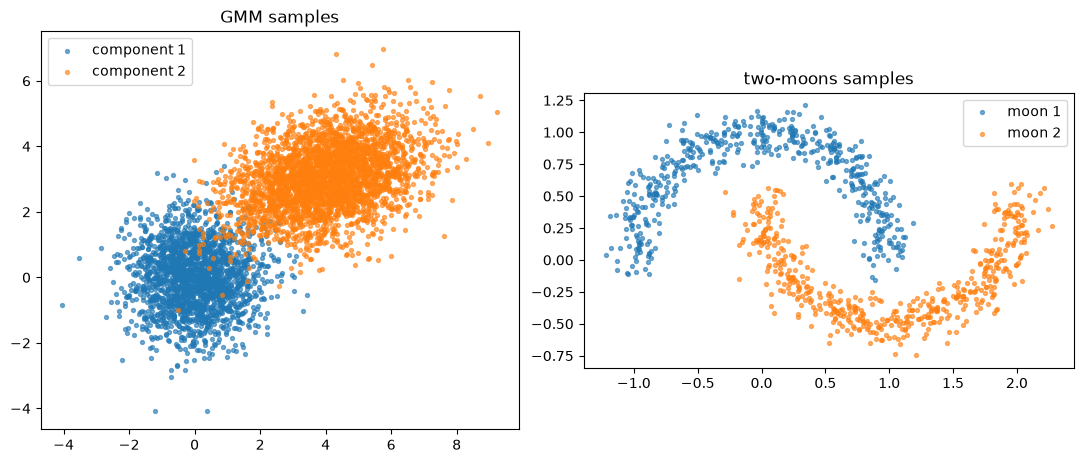

In [111]:
Xm, ym = make_moons(n_samples=1000, noise=0.1, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for k in range(2):
    axes[0].scatter(X[Z==k, 0], X[Z==k, 1], s=8, alpha=0.6, label=f"component {k+1}")

axes[0].set_title("GMM samples")
axes[0].legend(); axes[0].set_aspect('equal')

for k in range(2):
    axes[1].scatter(Xm[ym==k, 0], Xm[ym==k, 1], s=8, alpha=0.6, label=f"moon {k+1}")

axes[1].set_title("two-moons samples")
axes[1].legend(); axes[1].set_aspect('equal')

plt.tight_layout()
plt.show()